In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics opencv-python grad-cam scikit-learn

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#importing data
import os, shutil, random

DRIVE_ROOT   = "/content/drive/MyDrive/slugclassification"
SRC_IMAGES   = f"{DRIVE_ROOT}/slugsample500"          #all 250 raw images
SLUG_FOLDER  = f"{DRIVE_ROOT}/merged_slugdetection"           #merged CVAT annotation export (saniya 250 + anusha 250)
LABELS_DIR   = f"{SLUG_FOLDER}/labels/train"           #existing label .txt files from CVAT export

In [ ]:
#updating dataset structure (one imported from cvat only contains labels not images)
DATASET_DIR = "/content/dataset"
os.makedirs(f"{DATASET_DIR}/images/train", exist_ok=True)
os.makedirs(f"{DATASET_DIR}/images/val", exist_ok=True)
os.makedirs(f"{DATASET_DIR}/labels/train", exist_ok=True)
os.makedirs(f"{DATASET_DIR}/labels/val", exist_ok=True)

all_images = sorted([f for f in os.listdir(SRC_IMAGES) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
print(f"Total images found: {len(all_images)}")

label_files = {f.replace('.txt', '') for f in os.listdir(LABELS_DIR) if f.endswith('.txt')}
print(f"Total label files found: {len(label_files)}")

has_label = [f for f in all_images if os.path.splitext(f)[0] in label_files]
no_label  = [f for f in all_images if os.path.splitext(f)[0] not in label_files]
print(f"Images with slug labels: {len(has_label)}")
print(f"Images without labels (empty/background): {len(no_label)}")

random.seed(42)
random.shuffle(has_label)
random.shuffle(no_label)

def split(lst, frac=0.8):
    n = int(len(lst) * frac)
    return lst[:n], lst[n:]

train_pos, val_pos = split(has_label)
train_neg, val_neg = split(no_label)

train_set = train_pos + train_neg
val_set   = val_pos + val_neg
random.shuffle(train_set)
random.shuffle(val_set)

print(f"\nTrain: {len(train_set)} ({len(train_pos)} with slug, {len(train_neg)} empty)")
print(f"Val:   {len(val_set)} ({len(val_pos)} with slug, {len(val_neg)} empty)")

def populate(file_list, split_name):
    for fname in file_list:
        stem = os.path.splitext(fname)[0]
        shutil.copy(f"{SRC_IMAGES}/{fname}", f"{DATASET_DIR}/images/{split_name}/{fname}")
        src_label = f"{LABELS_DIR}/{stem}.txt"
        dst_label = f"{DATASET_DIR}/labels/{split_name}/{stem}.txt"
        if os.path.exists(src_label):
            shutil.copy(src_label, dst_label)
        else:
            open(dst_label, 'w').close()  # empty = background image, valid in YOLO

populate(train_set, "train")
populate(val_set, "val")

print("\nDataset built at:", DATASET_DIR)

Total images found: 500
Total label files found: 250
Images with slug labels: 250
Images without labels (empty/background): 250

Train: 400 (200 with slug, 200 empty)
Val:   100 (50 with slug, 50 empty)

Dataset built at: /content/dataset


In [ ]:
yaml_content = f"""path: {DATASET_DIR}
train: images/train
val: images/val
names:
  0: slug
"""
with open(f"{DATASET_DIR}/data.yaml", "w") as f:
    f.write(yaml_content)

print(yaml_content)

path: /content/dataset
train: images/train
val: images/val
names:
  0: slug



In [ ]:
#training YOLOv8 model
from ultralytics import YOLO
import pandas as pd

EPOCHS = 100
IMG_SIZE = 640

model = YOLO("yolov8s.pt")
train_results = model.train(
    data=f"{DATASET_DIR}/data.yaml",
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=16,
    project="/content/runs",
    name="yolov8",
    seed=42,
    patience=20,
    verbose=True
)

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.123 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, for

In [ ]:
#accuracy metrics (explicitly loads from current 500-image training run)
from ultralytics import YOLO
import pandas as pd

# Load from current run's best weights
current_best_pt = "/content/runs/yolov8/weights/best.pt"
model_eval = YOLO(current_best_pt)

val_metrics = model_eval.val(data=f"{DATASET_DIR}/data.yaml")

metrics_summary = {
    "mAP50": val_metrics.box.map50,
    "mAP50-95": val_metrics.box.map,
    "precision": val_metrics.box.mp,
    "recall": val_metrics.box.mr,
}

df_results = pd.DataFrame([metrics_summary], index=["yolov8_500img"])
print(df_results)
df_results.to_csv(f"{DRIVE_ROOT}/yolov8_500img_metrics.csv")

# Save new weights to Drive with a distinct name so old 250-image weights aren't overwritten
shutil.copy(current_best_pt, f"{DRIVE_ROOT}/slugdetection_yolov8_500img_best.pt")
print("Weights saved to Drive as slugdetection_yolov8_500img_best.pt")

Ultralytics 8.4.123 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2659.5±706.5 MB/s, size: 145.3 KB)
val: Scanning /content/dataset/labels/val.cache... 100 images, 50 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 30.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.5it/s 2.0s
                   all        100         50      0.999          1      0.995      0.888
Speed: 3.9ms preprocess, 5.3ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val-2
               mAP50  mAP50-95  precision  recall
yolov8_500img  0.995  0.887546   0.998779     1.0
Weights saved to Drive as slugdetection_yolov8_500img_best.pt


Total val images: 100
Slug-containing val images: 50
Running EigenCAM (layer 18) on 50 images...
Processed 10/50
Processed 20/50
Processed 30/50
Processed 40/50
Processed 50/50

All heatmaps saved to: /content/drive/MyDrive/slugclassification/eigencam_heatmaps_500img


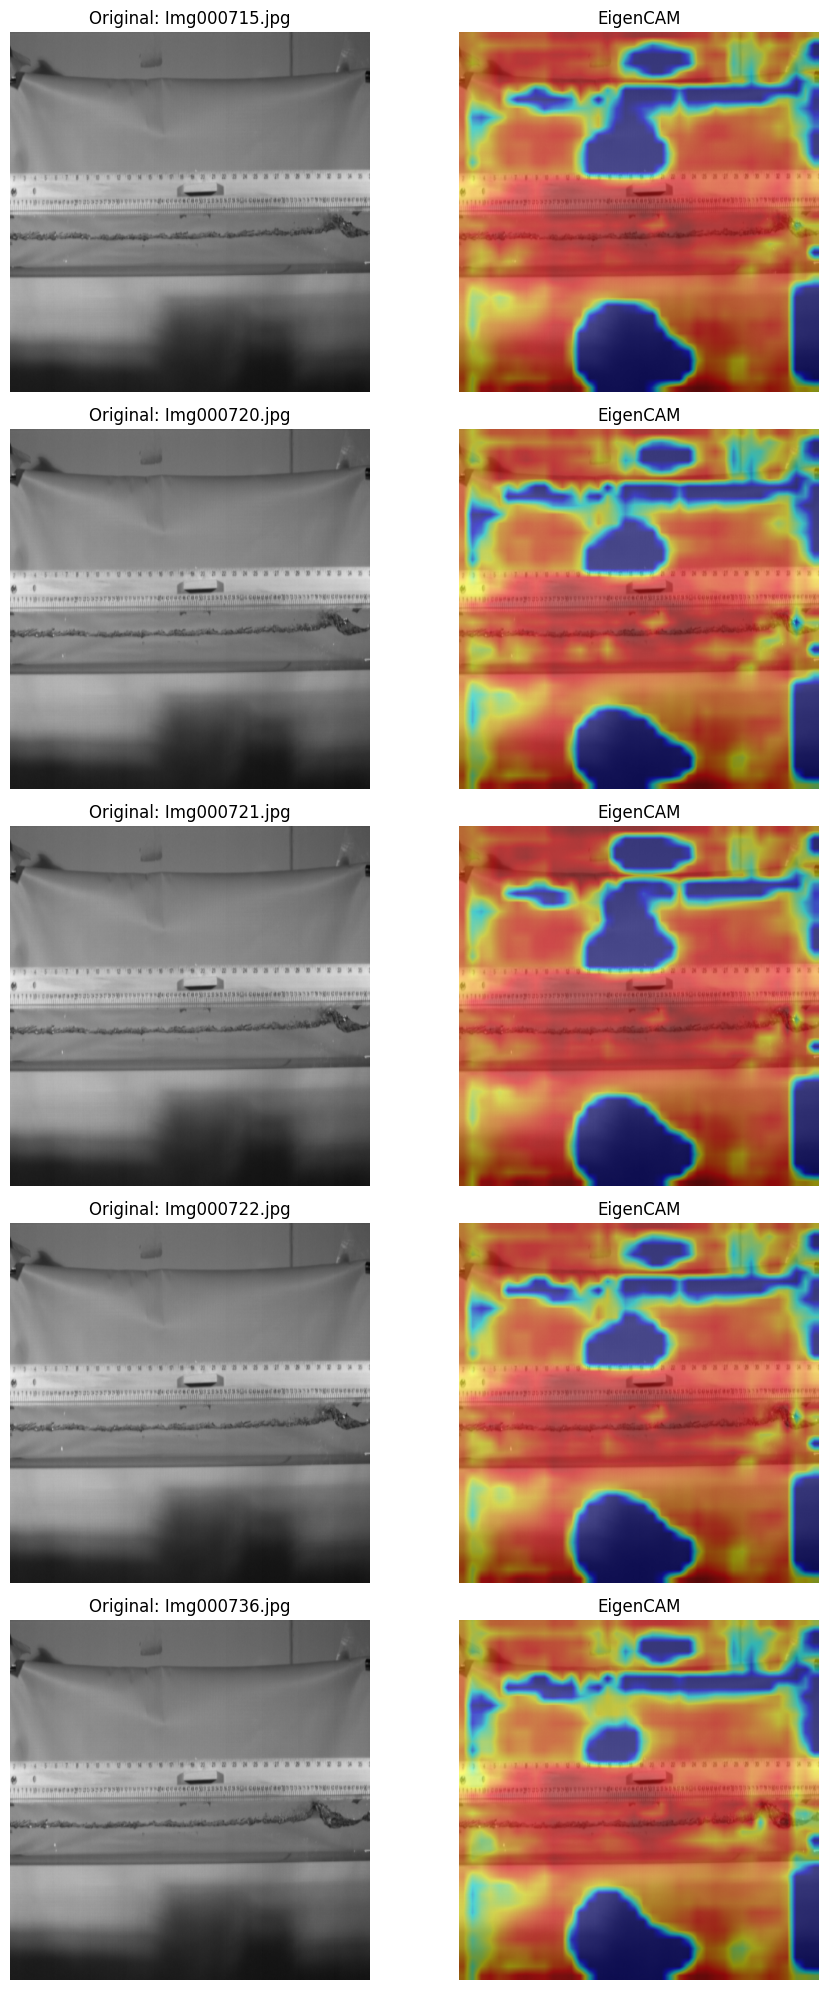

In [ ]:
#explainability (EigenCAM heatmaps - slug-containing val images only)
import cv2
import numpy as np
import torch
from pytorch_grad_cam import EigenCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt

BEST_LAYER = 18
from ultralytics import YOLO

# Reload fresh from saved weights to escape "inference tensor" lock
best_pt = "/content/runs/yolov8/weights/best.pt"
explain_model = YOLO(best_pt)

torch_model = explain_model.model
torch_model.eval()
for param in torch_model.parameters():
    param.requires_grad = True
if torch.cuda.is_available():
    torch_model.cuda()
torch_model.eval()
for param in torch_model.parameters():
    param.requires_grad = True
if torch.cuda.is_available():
    torch_model.cuda()

class YOLOClassScoreTarget:
    """Output shape [batch, 5, 8400]; channel 4 = class score for single 'slug' class."""
    def __call__(self, model_output):
        out = model_output[0] if isinstance(model_output, (tuple, list)) else model_output
        return out[:, 4, :].max()

target_layers = [torch_model.model[BEST_LAYER]]
cam = EigenCAM(torch_model, target_layers)

def get_eigencam_heatmap(img_path, img_size=640):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (img_size, img_size))
    rgb_img = img.copy()[:, :, ::-1]
    rgb_img = np.float32(rgb_img) / 255

    input_tensor = torch.from_numpy(rgb_img).permute(2, 0, 1).unsqueeze(0).float()
    input_tensor.requires_grad_(True)
    if torch.cuda.is_available():
        input_tensor = input_tensor.cuda()

    targets = [YOLOClassScoreTarget()]
    grayscale_cam = cam(input_tensor, targets=targets)[0, :, :]
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
    return cam_image, grayscale_cam, img

val_images_dir = f"{DATASET_DIR}/images/val"
labels_val_dir = f"{DATASET_DIR}/labels/val"
all_val_images = sorted(os.listdir(val_images_dir))

val_image_list = [
    f for f in all_val_images
    if os.path.exists(f"{labels_val_dir}/{os.path.splitext(f)[0]}.txt")
    and os.path.getsize(f"{labels_val_dir}/{os.path.splitext(f)[0]}.txt") > 0
]

print(f"Total val images: {len(all_val_images)}")
print(f"Slug-containing val images: {len(val_image_list)}")
print(f"Running EigenCAM (layer {BEST_LAYER}) on {len(val_image_list)} images...")

heatmaps = {}
HEATMAP_OUT_DIR = f"{DRIVE_ROOT}/eigencam_heatmaps_500img"
os.makedirs(HEATMAP_OUT_DIR, exist_ok=True)

for i, img_name in enumerate(val_image_list):
    img_path = f"{val_images_dir}/{img_name}"
    cam_image, grayscale_cam, orig = get_eigencam_heatmap(img_path)
    heatmaps[img_name] = grayscale_cam

    out_path = f"{HEATMAP_OUT_DIR}/{os.path.splitext(img_name)[0]}_cam.png"
    cv2.imwrite(out_path, cv2.cvtColor(cam_image, cv2.COLOR_RGB2BGR))

    if (i+1) % 10 == 0:
        print(f"Processed {i+1}/{len(val_image_list)}")

print(f"\nAll heatmaps saved to: {HEATMAP_OUT_DIR}")

fig, axes = plt.subplots(5, 2, figsize=(10, 20))
for i, img_name in enumerate(val_image_list[:5]):
    img_path = f"{val_images_dir}/{img_name}"
    cam_image, _, orig = get_eigencam_heatmap(img_path)
    axes[i, 0].imshow(orig[:, :, ::-1]); axes[i, 0].set_title(f"Original: {img_name}"); axes[i, 0].axis('off')
    axes[i, 1].imshow(cam_image); axes[i, 1].set_title("EigenCAM"); axes[i, 1].axis('off')
plt.tight_layout()
plt.savefig(f"{DRIVE_ROOT}/eigencam_sample_preview.png")
plt.show()

In [ ]:
#explainability (GradCAM++ heatmaps - slug-containing val images only)
import cv2
import numpy as np
import torch
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
from ultralytics import YOLO

BEST_LAYER = 18   # keep consistent with your EigenCAM choice, or pick separately

# Fresh reload to avoid "inference tensor" requires_grad error
best_pt = "/content/runs/yolov8/weights/best.pt"
explain_model_gc = YOLO(best_pt)

torch_model_gc = explain_model_gc.model
torch_model_gc.eval()
for param in torch_model_gc.parameters():
    param.requires_grad = True
if torch.cuda.is_available():
    torch_model_gc.cuda()

class YOLOClassScoreTarget:
    """Output shape [batch, 5, 8400]; channel 4 = class score for single 'slug' class."""
    def __call__(self, model_output):
        out = model_output[0] if isinstance(model_output, (tuple, list)) else model_output
        return out[:, 4, :].max()

target_layers_gc = [torch_model_gc.model[BEST_LAYER]]
cam_gc = GradCAMPlusPlus(torch_model_gc, target_layers_gc)

def get_gradcam_heatmap(img_path, img_size=640):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (img_size, img_size))
    rgb_img = img.copy()[:, :, ::-1]
    rgb_img = np.float32(rgb_img) / 255

    input_tensor = torch.from_numpy(rgb_img).permute(2, 0, 1).unsqueeze(0).float()
    input_tensor.requires_grad_(True)
    if torch.cuda.is_available():
        input_tensor = input_tensor.cuda()

    targets = [YOLOClassScoreTarget()]
    grayscale_cam = cam_gc(input_tensor, targets=targets)[0, :, :]
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
    return cam_image, grayscale_cam, img

val_images_dir = f"{DATASET_DIR}/images/val"
labels_val_dir = f"{DATASET_DIR}/labels/val"
all_val_images = sorted(os.listdir(val_images_dir))

val_image_list_gc = [
    f for f in all_val_images
    if os.path.exists(f"{labels_val_dir}/{os.path.splitext(f)[0]}.txt")
    and os.path.getsize(f"{labels_val_dir}/{os.path.splitext(f)[0]}.txt") > 0
]

print(f"Running GradCAM++ (layer {BEST_LAYER}) on {len(val_image_list_gc)} images...")

heatmaps_gc = {}
HEATMAP_OUT_DIR_GC = f"{DRIVE_ROOT}/gradcampp_heatmaps_500img"
os.makedirs(HEATMAP_OUT_DIR_GC, exist_ok=True)

for i, img_name in enumerate(val_image_list_gc):
    img_path = f"{val_images_dir}/{img_name}"
    cam_image, grayscale_cam, orig = get_gradcam_heatmap(img_path)
    heatmaps_gc[img_name] = grayscale_cam

    out_path = f"{HEATMAP_OUT_DIR_GC}/{os.path.splitext(img_name)[0]}_cam.png"

Running GradCAM++ (layer 18) on 50 images...


In [ ]:
#explainability metrics for GradCAM++ vs ground-truth bounding boxes
import numpy as np
import pandas as pd
import os

def yolo_box_to_mask(label_path, img_size=640):
    mask = np.zeros((img_size, img_size), dtype=np.uint8)
    if not os.path.exists(label_path) or os.path.getsize(label_path) == 0:
        return mask
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            _, xc, yc, w, h = map(float, parts)
            x1 = int((xc - w/2) * img_size)
            y1 = int((yc - h/2) * img_size)
            x2 = int((xc + w/2) * img_size)
            y2 = int((yc + h/2) * img_size)
            mask[max(0,y1):min(img_size,y2), max(0,x1):min(img_size,x2)] = 1
    return mask

def heatmap_to_mask(grayscale_cam, threshold=0.5):
    return (grayscale_cam >= threshold).astype(np.uint8)

def compute_metrics(gt_mask, pred_mask):
    gt = gt_mask.flatten()
    pred = pred_mask.flatten()
    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    gt_sum = gt.sum()
    pred_sum = pred.sum()
    iou = intersection / union if union > 0 else 0.0
    dice = (2 * intersection) / (gt_sum + pred_sum) if (gt_sum + pred_sum) > 0 else 0.0
    recall = intersection / gt_sum if gt_sum > 0 else 0.0
    return {"IoU": iou, "Dice": dice, "Recall": recall}

labels_val_dir = f"{DATASET_DIR}/labels/val"
all_metrics_gc = []

for img_name in val_image_list_gc:
    stem = os.path.splitext(img_name)[0]
    label_path = f"{labels_val_dir}/{stem}.txt"

    gt_mask = yolo_box_to_mask(label_path, img_size=640)
    if gt_mask.sum() == 0:
        continue

    pred_mask = heatmap_to_mask(heatmaps_gc[img_name], threshold=0.5)
    metrics = compute_metrics(gt_mask, pred_mask)
    metrics["image"] = img_name
    all_metrics_gc.append(metrics)

metrics_df_gc = pd.DataFrame(all_metrics_gc).set_index("image")
print(metrics_df_gc)
print(f"\nEvaluated on {len(metrics_df_gc)} slug-containing images")
print("\nMean metrics (GradCAM++):")
print(metrics_df_gc.mean(numeric_only=True))

metrics_df_gc.to_csv(f"{DRIVE_ROOT}/500_gradcampp_vs_gt_metrics.csv")

                    IoU      Dice    Recall
image                                      
Img000715.jpg  0.313745  0.477635  0.325229
Img000720.jpg  0.263210  0.416732  0.323030
Img000721.jpg  0.276572  0.433305  0.302738
Img000722.jpg  0.005323  0.010589  0.007526
Img000736.jpg  0.131886  0.233038  0.132631
Img000737.jpg  0.152105  0.264047  0.155172
Img000740.jpg  0.083940  0.154880  0.102581
Img000742.jpg  0.080138  0.148384  0.097238
Img000749.jpg  0.000000  0.000000  0.000000
Img000753.jpg  0.000000  0.000000  0.000000
Img000754.jpg  0.000000  0.000000  0.000000
Img000764.jpg  0.000000  0.000000  0.000000
Img000769.jpg  0.009350  0.018527  0.010536
Img000770.jpg  0.011627  0.022987  0.012990
Img000771.jpg  0.000000  0.000000  0.000000
Img000773.jpg  0.000000  0.000000  0.000000
Img000776.jpg  0.000000  0.000000  0.000000
Img000784.jpg  0.000000  0.000000  0.000000
Img000785.jpg  0.000000  0.000000  0.000000
Img000800.jpg  0.080338  0.148728  0.081590
Img000801.jpg  0.052129  0.09909

In [ ]:
#explainability metrics for EigenCAM vs ground-truth bounding boxes
import numpy as np
import pandas as pd
import os

def yolo_box_to_mask(label_path, img_size=640):
    mask = np.zeros((img_size, img_size), dtype=np.uint8)
    if not os.path.exists(label_path) or os.path.getsize(label_path) == 0:
        return mask
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            _, xc, yc, w, h = map(float, parts)
            x1 = int((xc - w/2) * img_size)
            y1 = int((yc - h/2) * img_size)
            x2 = int((xc + w/2) * img_size)
            y2 = int((yc + h/2) * img_size)
            mask[max(0,y1):min(img_size,y2), max(0,x1):min(img_size,x2)] = 1
    return mask

def heatmap_to_mask(grayscale_cam, threshold=0.5):
    return (grayscale_cam >= threshold).astype(np.uint8)

def compute_metrics(gt_mask, pred_mask):
    gt = gt_mask.flatten()
    pred = pred_mask.flatten()
    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    gt_sum = gt.sum()
    pred_sum = pred.sum()
    iou = intersection / union if union > 0 else 0.0
    dice = (2 * intersection) / (gt_sum + pred_sum) if (gt_sum + pred_sum) > 0 else 0.0
    recall = intersection / gt_sum if gt_sum > 0 else 0.0
    return {"IoU": iou, "Dice": dice, "Recall": recall}

labels_val_dir = f"{DATASET_DIR}/labels/val"
all_metrics = []

for img_name in val_image_list:
    stem = os.path.splitext(img_name)[0]
    label_path = f"{labels_val_dir}/{stem}.txt"

    gt_mask = yolo_box_to_mask(label_path, img_size=640)
    if gt_mask.sum() == 0:
        continue

    pred_mask = heatmap_to_mask(heatmaps[img_name], threshold=0.5)
    metrics = compute_metrics(gt_mask, pred_mask)
    metrics["image"] = img_name
    all_metrics.append(metrics)

metrics_df = pd.DataFrame(all_metrics).set_index("image")
print(metrics_df)
print(f"\nEvaluated on {len(metrics_df)} slug-containing images")
print("\nMean metrics (EigenCAM):")
print(metrics_df.mean(numeric_only=True))

metrics_df.to_csv(f"{DRIVE_ROOT}/500_eigencam_vs_gt_metrics.csv")

                    IoU      Dice    Recall
image                                      
Img000715.jpg  0.011876  0.023474  0.996863
Img000720.jpg  0.014273  0.028144  0.917778
Img000721.jpg  0.015328  0.030194  0.997987
Img000722.jpg  0.015350  0.030236  0.979996
Img000736.jpg  0.019203  0.037682  0.934524
Img000737.jpg  0.019657  0.038556  0.967057
Img000740.jpg  0.022899  0.044773  0.933935
Img000742.jpg  0.025874  0.050443  0.953237
Img000749.jpg  0.031765  0.061575  0.992308
Img000753.jpg  0.039017  0.075104  0.943991
Img000754.jpg  0.038401  0.073962  0.909468
Img000764.jpg  0.045054  0.086223  0.986661
Img000769.jpg  0.043347  0.083092  0.743095
Img000770.jpg  0.043123  0.082680  0.745572
Img000771.jpg  0.045958  0.087877  0.756623
Img000773.jpg  0.051028  0.097101  0.869634
Img000776.jpg  0.059122  0.111644  0.981081
Img000784.jpg  0.073982  0.137772  0.946460
Img000785.jpg  0.067549  0.126550  0.887275
Img000800.jpg  0.093989  0.171829  0.874149
Img000801.jpg  0.086385  0.15903

Running EigenGradCAM on 50 slug-containing val images...
Processed 10/50
Processed 20/50
Processed 30/50
Processed 40/50
Processed 50/50

All EigenGradCAM heatmaps saved to: /content/drive/MyDrive/slugclassification/eigengradcam_heatmaps_500img


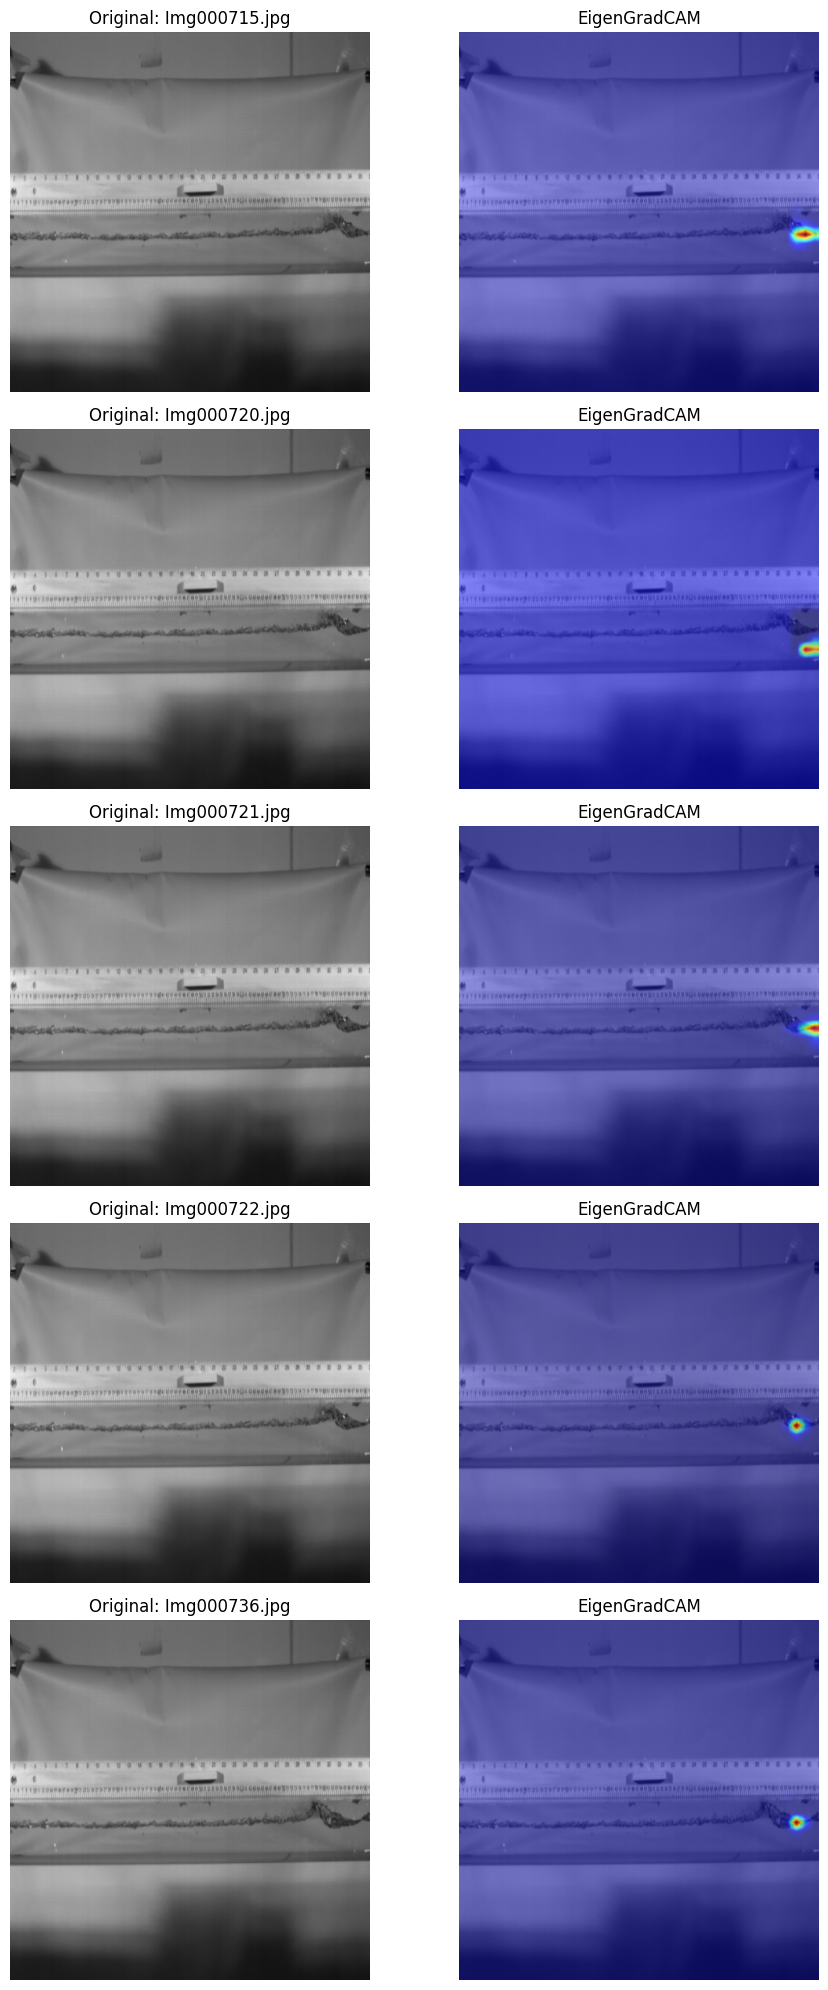

In [ ]:
#now trying eigengradcam
# EigenGradCAM - third explainability method (direct pytorch-grad-cam implementation)
import cv2
import numpy as np
import torch
from pytorch_grad_cam import EigenGradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
from ultralytics import YOLO

BEST_LAYER = 18

best_pt = "/content/runs/yolov8/weights/best.pt"
explain_model_eg = YOLO(best_pt)

torch_model_eg = explain_model_eg.model
torch_model_eg.eval()
for param in torch_model_eg.parameters():
    param.requires_grad = True
if torch.cuda.is_available():
    torch_model_eg.cuda()

class YOLOClassScoreTarget:
    def __call__(self, model_output):
        out = model_output[0] if isinstance(model_output, (tuple, list)) else model_output
        return out[:, 4, :].max()

target_layers_eg = [torch_model_eg.model[BEST_LAYER]]
cam_eg = EigenGradCAM(torch_model_eg, target_layers_eg)

def get_eigengradcam_heatmap(img_path, img_size=640):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (img_size, img_size))
    rgb_img = img.copy()[:, :, ::-1]
    rgb_img = np.float32(rgb_img) / 255

    input_tensor = torch.from_numpy(rgb_img).permute(2, 0, 1).unsqueeze(0).float()
    input_tensor.requires_grad_(True)
    if torch.cuda.is_available():
        input_tensor = input_tensor.cuda()

    targets = [YOLOClassScoreTarget()]
    grayscale_cam = cam_eg(input_tensor, targets=targets)[0, :, :]
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
    return cam_image, grayscale_cam, img

val_images_dir = f"{DATASET_DIR}/images/val"
labels_val_dir = f"{DATASET_DIR}/labels/val"
all_val_images = sorted(os.listdir(val_images_dir))

val_image_list_eg = [
    f for f in all_val_images
    if os.path.exists(f"{labels_val_dir}/{os.path.splitext(f)[0]}.txt")
    and os.path.getsize(f"{labels_val_dir}/{os.path.splitext(f)[0]}.txt") > 0
]

print(f"Running EigenGradCAM on {len(val_image_list_eg)} slug-containing val images...")

HEATMAP_OUT_DIR_EG = f"{DRIVE_ROOT}/eigengradcam_heatmaps_500img"
os.makedirs(HEATMAP_OUT_DIR_EG, exist_ok=True)

heatmaps_eg = {}

for i, img_name in enumerate(val_image_list_eg):
    img_path = f"{val_images_dir}/{img_name}"
    cam_image, grayscale_cam, orig = get_eigengradcam_heatmap(img_path)
    heatmaps_eg[img_name] = grayscale_cam

    out_path = f"{HEATMAP_OUT_DIR_EG}/{os.path.splitext(img_name)[0]}_cam.png"
    cv2.imwrite(out_path, cv2.cvtColor(cam_image, cv2.COLOR_RGB2BGR))

    if (i+1) % 10 == 0:
        print(f"Processed {i+1}/{len(val_image_list_eg)}")

print(f"\nAll EigenGradCAM heatmaps saved to: {HEATMAP_OUT_DIR_EG}")

fig, axes = plt.subplots(5, 2, figsize=(10, 20))
for i, img_name in enumerate(val_image_list_eg[:5]):
    img_path = f"{val_images_dir}/{img_name}"
    cam_image, _, orig = get_eigengradcam_heatmap(img_path)
    axes[i, 0].imshow(orig[:, :, ::-1]); axes[i, 0].set_title(f"Original: {img_name}"); axes[i, 0].axis('off')
    axes[i, 1].imshow(cam_image); axes[i, 1].set_title("EigenGradCAM"); axes[i, 1].axis('off')
plt.tight_layout()
plt.savefig(f"{DRIVE_ROOT}/eigengradcam_sample_preview.png")
plt.show()

In [ ]:
# EigenGradCAM metrics vs ground-truth bounding boxes
import numpy as np
import pandas as pd
import os

def yolo_box_to_mask(label_path, img_size=640):
    mask = np.zeros((img_size, img_size), dtype=np.uint8)
    if not os.path.exists(label_path) or os.path.getsize(label_path) == 0:
        return mask
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            _, xc, yc, w, h = map(float, parts)
            x1 = int((xc - w/2) * img_size)
            y1 = int((yc - h/2) * img_size)
            x2 = int((xc + w/2) * img_size)
            y2 = int((yc + h/2) * img_size)
            mask[max(0,y1):min(img_size,y2), max(0,x1):min(img_size,x2)] = 1
    return mask

def heatmap_to_mask(grayscale_cam, threshold=0.5):
    return (grayscale_cam >= threshold).astype(np.uint8)

def compute_metrics(gt_mask, pred_mask):
    gt = gt_mask.flatten()
    pred = pred_mask.flatten()
    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    gt_sum = gt.sum()
    pred_sum = pred.sum()
    iou = intersection / union if union > 0 else 0.0
    dice = (2 * intersection) / (gt_sum + pred_sum) if (gt_sum + pred_sum) > 0 else 0.0
    recall = intersection / gt_sum if gt_sum > 0 else 0.0
    return {"IoU": iou, "Dice": dice, "Recall": recall}

labels_val_dir = f"{DATASET_DIR}/labels/val"
all_metrics_eg = []

for img_name in val_image_list_eg:
    stem = os.path.splitext(img_name)[0]
    label_path = f"{labels_val_dir}/{stem}.txt"

    gt_mask = yolo_box_to_mask(label_path, img_size=640)
    if gt_mask.sum() == 0:
        continue

    pred_mask = heatmap_to_mask(heatmaps_eg[img_name], threshold=0.5)
    metrics = compute_metrics(gt_mask, pred_mask)
    metrics["image"] = img_name
    all_metrics_eg.append(metrics)

metrics_df_eg = pd.DataFrame(all_metrics_eg).set_index("image")
print(metrics_df_eg)
print(f"\nEvaluated on {len(metrics_df_eg)} slug-containing images")
print("\nMean metrics (EigenGradCAM):")
print(metrics_df_eg.mean(numeric_only=True))

# Combined summary across all three methods
print("\n=== Summary: All Explainability Methods ===")
summary = pd.DataFrame({
    "EigenCAM":     [0.095522, 0.168784, 0.900679],
    "GradCAM++":    [0.056240, 0.097710, 0.069666],
    "EigenGradCAM": metrics_df_eg.mean(numeric_only=True).values
}, index=["IoU", "Dice", "Recall"])
print(summary)

metrics_df_eg.to_csv(f"{DRIVE_ROOT}/500_eigengradcam_vs_gt_metrics.csv")
summary.to_csv(f"{DRIVE_ROOT}/500_explainability_summary.csv")

                    IoU      Dice    Recall
image                                      
Img000715.jpg  0.141551  0.247998  0.141699
Img000720.jpg  0.000000  0.000000  0.000000
Img000721.jpg  0.071787  0.133957  0.072061
Img000722.jpg  0.047911  0.091442  0.047930
Img000736.jpg  0.033730  0.065259  0.033730
Img000737.jpg  0.029249  0.056835  0.029249
Img000740.jpg  0.029677  0.057644  0.029677
Img000742.jpg  0.072407  0.135036  0.072407
Img000749.jpg  0.046454  0.088783  0.046454
Img000753.jpg  0.046690  0.089215  0.046819
Img000754.jpg  0.025223  0.049204  0.025274
Img000764.jpg  0.072745  0.135624  0.072745
Img000769.jpg  0.039702  0.076373  0.039702
Img000770.jpg  0.037435  0.072168  0.037435
Img000771.jpg  0.034585  0.066858  0.034585
Img000773.jpg  0.035941  0.069389  0.035941
Img000776.jpg  0.022660  0.044317  0.022660
Img000784.jpg  0.019329  0.037925  0.019329
Img000785.jpg  0.017268  0.033951  0.017268
Img000800.jpg  0.006166  0.012256  0.006169
Img000801.jpg  0.017685  0.03475

Running LayerCAM on 50 slug-containing val images...
Processed 10/50
Processed 20/50
Processed 30/50
Processed 40/50
Processed 50/50

All LayerCAM heatmaps saved to: /content/drive/MyDrive/slugclassification/layercam_heatmaps_500img


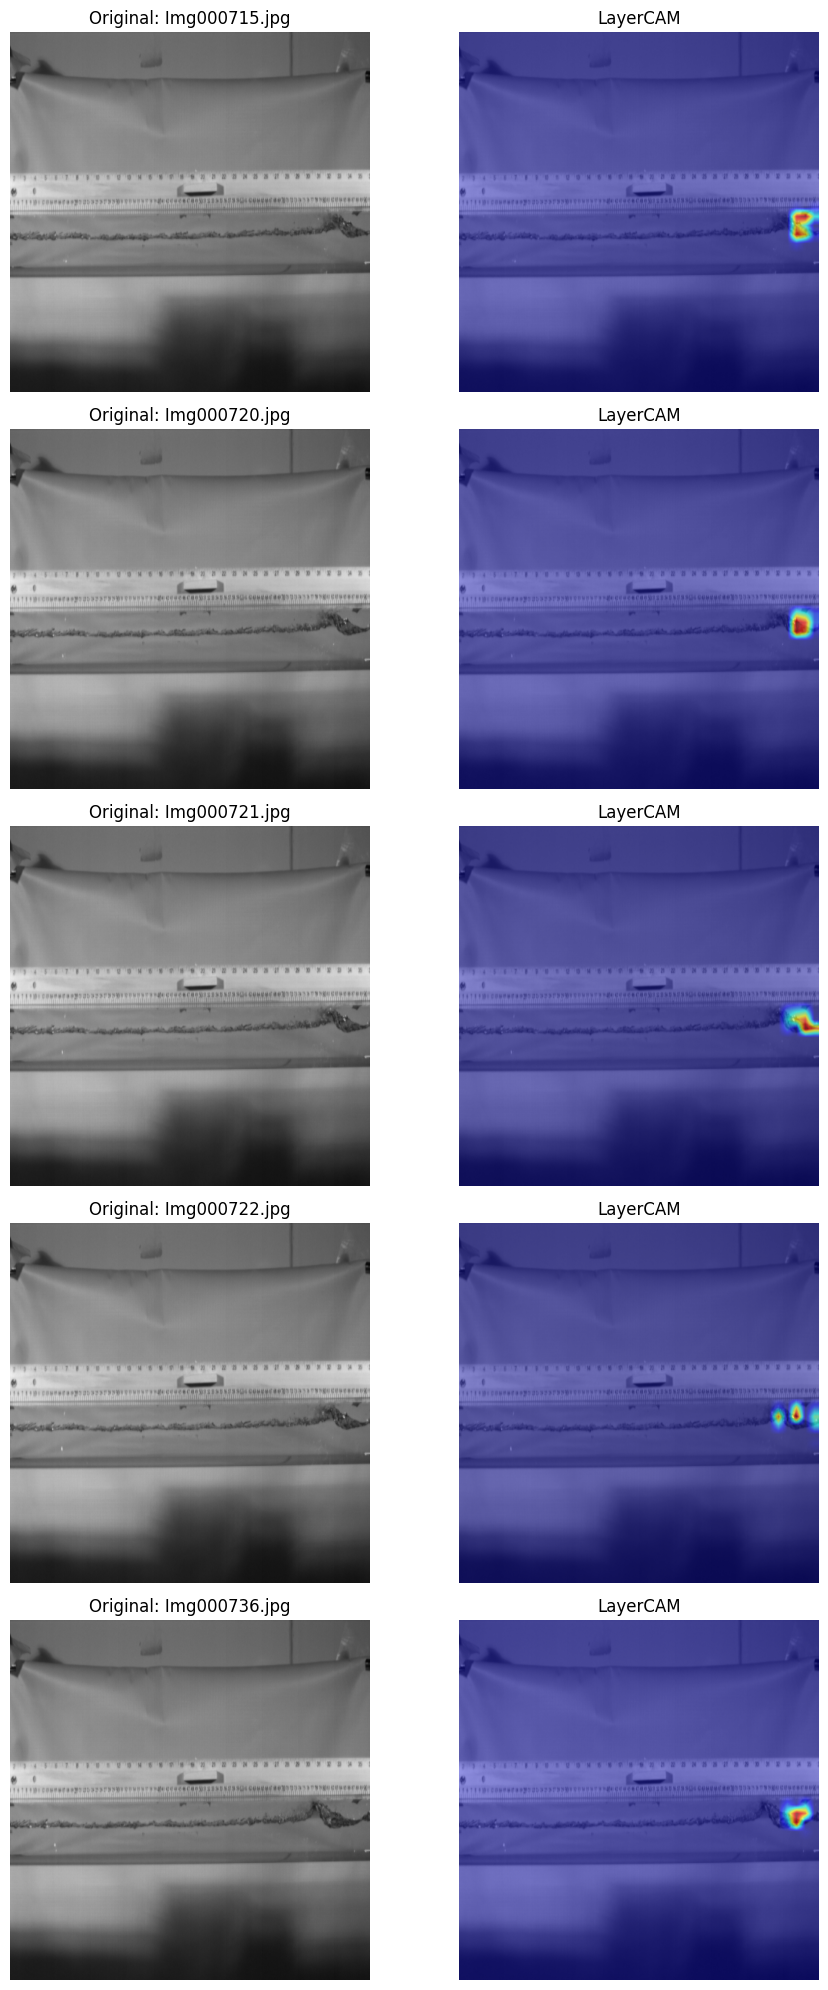

In [ ]:
#layercam
# LayerCAM - third explainability method
import cv2
import numpy as np
import torch
from pytorch_grad_cam import LayerCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
from ultralytics import YOLO

BEST_LAYER = 18

best_pt = "/content/runs/yolov8/weights/best.pt"
explain_model_lc = YOLO(best_pt)

torch_model_lc = explain_model_lc.model
torch_model_lc.eval()
for param in torch_model_lc.parameters():
    param.requires_grad = True
if torch.cuda.is_available():
    torch_model_lc.cuda()

class YOLOClassScoreTarget:
    def __call__(self, model_output):
        out = model_output[0] if isinstance(model_output, (tuple, list)) else model_output
        return out[:, 4, :].max()

target_layers_lc = [torch_model_lc.model[BEST_LAYER]]
cam_lc = LayerCAM(torch_model_lc, target_layers_lc)

def get_layercam_heatmap(img_path, img_size=640):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (img_size, img_size))
    rgb_img = img.copy()[:, :, ::-1]
    rgb_img = np.float32(rgb_img) / 255

    input_tensor = torch.from_numpy(rgb_img).permute(2, 0, 1).unsqueeze(0).float()
    input_tensor.requires_grad_(True)
    if torch.cuda.is_available():
        input_tensor = input_tensor.cuda()

    targets = [YOLOClassScoreTarget()]
    grayscale_cam = cam_lc(input_tensor, targets=targets)[0, :, :]
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
    return cam_image, grayscale_cam, img

val_images_dir = f"{DATASET_DIR}/images/val"
labels_val_dir = f"{DATASET_DIR}/labels/val"
all_val_images = sorted(os.listdir(val_images_dir))

val_image_list_lc = [
    f for f in all_val_images
    if os.path.exists(f"{labels_val_dir}/{os.path.splitext(f)[0]}.txt")
    and os.path.getsize(f"{labels_val_dir}/{os.path.splitext(f)[0]}.txt") > 0
]

print(f"Running LayerCAM on {len(val_image_list_lc)} slug-containing val images...")

HEATMAP_OUT_DIR_LC = f"{DRIVE_ROOT}/layercam_heatmaps_500img"
os.makedirs(HEATMAP_OUT_DIR_LC, exist_ok=True)

heatmaps_lc = {}

for i, img_name in enumerate(val_image_list_lc):
    img_path = f"{val_images_dir}/{img_name}"
    cam_image, grayscale_cam, orig = get_layercam_heatmap(img_path)
    heatmaps_lc[img_name] = grayscale_cam

    out_path = f"{HEATMAP_OUT_DIR_LC}/{os.path.splitext(img_name)[0]}_cam.png"
    cv2.imwrite(out_path, cv2.cvtColor(cam_image, cv2.COLOR_RGB2BGR))

    if (i+1) % 10 == 0:
        print(f"Processed {i+1}/{len(val_image_list_lc)}")

print(f"\nAll LayerCAM heatmaps saved to: {HEATMAP_OUT_DIR_LC}")

fig, axes = plt.subplots(5, 2, figsize=(10, 20))
for i, img_name in enumerate(val_image_list_lc[:5]):
    img_path = f"{val_images_dir}/{img_name}"
    cam_image, _, orig = get_layercam_heatmap(img_path)
    axes[i, 0].imshow(orig[:, :, ::-1]); axes[i, 0].set_title(f"Original: {img_name}"); axes[i, 0].axis('off')
    axes[i, 1].imshow(cam_image); axes[i, 1].set_title("LayerCAM"); axes[i, 1].axis('off')
plt.tight_layout()
plt.savefig(f"{DRIVE_ROOT}/layercam_sample_preview.png")
plt.show()

In [ ]:
# LayerCAM metrics vs ground-truth bounding boxes
import numpy as np
import pandas as pd
import os

def yolo_box_to_mask(label_path, img_size=640):
    mask = np.zeros((img_size, img_size), dtype=np.uint8)
    if not os.path.exists(label_path) or os.path.getsize(label_path) == 0:
        return mask
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            _, xc, yc, w, h = map(float, parts)
            x1 = int((xc - w/2) * img_size)
            y1 = int((yc - h/2) * img_size)
            x2 = int((xc + w/2) * img_size)
            y2 = int((yc + h/2) * img_size)
            mask[max(0,y1):min(img_size,y2), max(0,x1):min(img_size,x2)] = 1
    return mask

def heatmap_to_mask(grayscale_cam, threshold=0.5):
    return (grayscale_cam >= threshold).astype(np.uint8)

def compute_metrics(gt_mask, pred_mask):
    gt = gt_mask.flatten()
    pred = pred_mask.flatten()
    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    gt_sum = gt.sum()
    pred_sum = pred.sum()
    iou = intersection / union if union > 0 else 0.0
    dice = (2 * intersection) / (gt_sum + pred_sum) if (gt_sum + pred_sum) > 0 else 0.0
    recall = intersection / gt_sum if gt_sum > 0 else 0.0
    return {"IoU": iou, "Dice": dice, "Recall": recall}

labels_val_dir = f"{DATASET_DIR}/labels/val"
all_metrics_lc = []

for img_name in val_image_list_lc:
    stem = os.path.splitext(img_name)[0]
    label_path = f"{labels_val_dir}/{stem}.txt"

    gt_mask = yolo_box_to_mask(label_path, img_size=640)
    if gt_mask.sum() == 0:
        continue

    pred_mask = heatmap_to_mask(heatmaps_lc[img_name], threshold=0.5)
    metrics = compute_metrics(gt_mask, pred_mask)
    metrics["image"] = img_name
    all_metrics_lc.append(metrics)

metrics_df_lc = pd.DataFrame(all_metrics_lc).set_index("image")
print(metrics_df_lc)
print(f"\nEvaluated on {len(metrics_df_lc)} slug-containing images")
print("\nMean metrics (LayerCAM):")
print(metrics_df_lc.mean(numeric_only=True))

# Combined summary across all three methods
print("\n=== Summary: All Explainability Methods ===")
summary = pd.DataFrame({
    "EigenCAM":  [0.095522, 0.168784, 0.900679],
    "GradCAM++": [0.056240, 0.097710, 0.069666],
    "LayerCAM":  metrics_df_lc.mean(numeric_only=True).values
}, index=["IoU", "Dice", "Recall"])
print(summary)

metrics_df_lc.to_csv(f"{DRIVE_ROOT}/500_layercam_vs_gt_metrics.csv")
summary.to_csv(f"{DRIVE_ROOT}/500_explainability_summary.csv")

                    IoU      Dice    Recall
image                                      
Img000715.jpg  0.309020  0.472139  0.309020
Img000720.jpg  0.210909  0.348348  0.210909
Img000721.jpg  0.181928  0.307849  0.182367
Img000722.jpg  0.082393  0.152242  0.082393
Img000736.jpg  0.117979  0.211058  0.117979
Img000737.jpg  0.116533  0.208741  0.116533
Img000740.jpg  0.028387  0.055207  0.028387
Img000742.jpg  0.029937  0.058134  0.029937
Img000749.jpg  0.071728  0.133855  0.071728
Img000753.jpg  0.055224  0.104668  0.055224
Img000754.jpg  0.027052  0.052680  0.027074
Img000764.jpg  0.043867  0.084047  0.043867
Img000769.jpg  0.020476  0.040131  0.020476
Img000770.jpg  0.019190  0.037657  0.019190
Img000771.jpg  0.026608  0.051838  0.026608
Img000773.jpg  0.042471  0.081481  0.042471
Img000776.jpg  0.028967  0.056303  0.028967
Img000784.jpg  0.028682  0.055764  0.028682
Img000785.jpg  0.029086  0.056528  0.029086
Img000800.jpg  0.020668  0.040498  0.020668
Img000801.jpg  0.027029  0.05263